# 9. Cosmological constraints from the halo mass function

This notebook follows Sec. 4.3 of Paper I.
We forecast what a perfect census of haloes constrains: every halo above a mass threshold, its $M_{200{\rm m}}$ known exactly, counted in mass bins and redshift shells over 20 000 deg², with Poisson and super-sample errors.
The forecast is in flat $\Lambda$CDM with the BBN and $n_{\rm s}$ priors of notebook 08, at four thresholds.
The machinery is in `_forecast.py`; each cell calls one piece and says what it does.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, sigma8
from ggah_mod.cosmology.background import comoving_volume_element
from ggah_mod.cosmology.domain import domain_margins
from ggah_mod.covariance.supersample import slab_sigma2_b
from ggah_mod.halos.field import make_fields
from ggah_mod.spectra.pk import PkOptions

import _forecast as F

c0 = PLANCK18
PX, P5, PS8 = F._HMF_PX, F._HMF_P, F._HMF_PS8
npar = len(P5)
THRESH, SHELLS = F._HMF_THRESH, F._HMF_SHELLS

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


$HOME/software/ggah_mod/ggah_mod/covariance/__init__.py:47: WorkInProgressWarning: ggah_mod.covariance is work in progress. Layers 3 to 6 of ggah_mod (sectors, spectra, observables, covariance) and its interfaces are released as tested code ahead of their verification; their interface and results may change. Every layer is documented at https://ggah-mod.readthedocs.io.
  warn_work_in_progress(__name__)


## The mock measurement and the model

The counts in shell $a$ and mass bin $i$ are (Eq. 47)

$$N_{ai} = \Omega\int_a{\rm d}z\,\frac{{\rm d}V}{{\rm d}z\,{\rm d}\Omega}\int_i{\rm d}\ln M\,M\frac{{\rm d}n}{{\rm d}M},$$

with ${\rm d}n/{\rm d}M$ the `tinker08` mass function of notebook 05 on the cold spectrum of `emu_pk`, and ${\rm d}V/{\rm d}z\,{\rm d}\Omega = D_H f_K^2/E$.
The volume element moves with the cosmology as the mass function does, so the counts carry the distances too.
Bins are 0.1 dex wide, from the threshold to $10^{15.5}\,h^{-1}{\rm M}_\odot$, integrated on Gauss–Legendre nodes in $z$ and $\ln M$.
`_hmf_setup()` evaluates the counts at the fiducial, their Jacobian by one `jax.jacfwd`, and the covariance below.
The chain per redshift is the one `make_field` runs; we check that first.

In [2]:
st = F._hmf_setup()
emu, counts, aux, t0x = st["emu"], st["counts"], st["aux"], st["t0"]
n0, b0, C, S = st["n0"], st["b0"], st["C"], st["S"]
t0 = t0x[:npar]

zn = aux["zn"]
msub = 10.0 ** aux["bins"][0][1].ravel()
zt = (float(zn[0]), float(zn[-1]))
flds = make_fields(c0, DIFFERENTIABLE, emu, z=zt, m=msub, mdef="200m", hmf_model="tinker08", bias_model="tinker10")
dev = 0.0
for f, z in zip(flds, zt):
    dn, b = aux["per_z"](c0, z)
    dev = max(dev, float(np.max(np.abs(np.asarray(dn[:msub.size]) / np.asarray(f.m * f.dndm) - 1))),
              float(np.max(np.abs(np.asarray(b[:msub.size]) / np.asarray(f.bias) - 1))))
print(f"loose chain against make_fields: {dev:.0e}")

zn_, wz_ = F._hmf_znodes(32)
vol = (np.asarray(comoving_volume_element(jnp.asarray(zn_), c0)) * wz_ * aux["omega"]).reshape(len(SHELLS), -1).sum(1)
print(f"f_sky = {st['geo'].f_sky:.3f}; shell volumes [(Gpc/h)^3]: " + "  ".join(f"{v / 1e9:.2f}" for v in vol))
for i, th in enumerate(THRESH):
    print(f"M > {th:.0e}: {n0[i].shape[1]} bins per shell, N = {n0[i].sum():,.0f}")

loose chain against make_fields: 3e-15
f_sky = 0.485; shell volumes [(Gpc/h)^3]: 0.33  0.80  1.39  2.05
M > 5e+13: 18 bins per shell, N = 243,701
M > 1e+14: 15 bins per shell, N = 79,236
M > 3e+14: 10 bins per shell, N = 7,924
M > 5e+14: 8 bins per shell, N = 1,940


## The covariance

Two terms (Eq. 47):

$$\mathsf{C}_{ai,bj} = \delta_{ab}\delta_{ij}N_{ai} + b_{ai}N_{ai}\,b_{bj}N_{bj}\,S_{ab}.$$

The first is Poisson.
The second is the sample variance of the haloes: a density mode longer than the survey raises or lowers every count in a shell together, each by its bias times itself.
$S_{ab}$ is that mode's covariance between two shells, summed exactly to $\ell = 200$ over the footprint's mask power, since Limber's approximation correlates no two disjoint shells.
Its diagonal is the super-sample variance, which `slab_sigma2_b` of the covariance layer computes; we check the two agree.

In [3]:
opts = PkOptions.from_backend(DIFFERENTIABLE)
fields_at = lambda zz: make_fields(c0, DIFFERENTIABLE, emu, z=zz, mdef="200m", hmf_model="tinker08", bias_model="tinker10")
ref = np.array([float(slab_sigma2_b(st["geo"].with_slab(a, b), c0, fields_at, opts,
                                    k_max=F._HMF_SSC_KMAX, k_per_period=F._HMF_SSC_KPP)) for a, b in SHELLS])
sdev = float(np.max(np.abs(np.diag(S) / ref - 1)))
sb = np.sqrt(np.diag(S))
print(f"diagonal against slab_sigma2_b: {sdev:.1e}")
print("sigma_b per shell: " + "  ".join(f"{x:.4f}" for x in sb))
print("adjacent-shell correlation: " + "  ".join(f"{S[a, a + 1] / (sb[a] * sb[a + 1]):+.2f}" for a in range(3)))
for i, th in enumerate(THRESH):
    frac = (b0[i] * n0[i]) ** 2 * np.diag(S)[:, None] / n0[i]
    print(f"M > {th:.0e}: super-sample / Poisson variance, first bin: "
          + " ".join(f"{x:.2f}" for x in frac[:, 0]))

diagonal against slab_sigma2_b: 3.5e-04
sigma_b per shell: 0.0065  0.0039  0.0028  0.0022
adjacent-shell correlation: -0.18  -0.21  -0.22
M > 5e+13: super-sample / Poisson variance, first bin: 0.98 0.92 0.88 0.84
M > 1e+14: super-sample / Poisson variance, first bin: 0.66 0.60 0.55 0.50
M > 3e+14: super-sample / Poisson variance, first bin: 0.27 0.23 0.19 0.15
M > 5e+14: super-sample / Poisson variance, first bin: 0.15 0.11 0.09 0.06


## The Jacobian and the priors

We check the Jacobian against central differences over all counts and seven parameters.
Alone, the counts constrain neither $h$, $\Omega_{\rm b}$ nor $n_{\rm s}$: the condition number of $F$ is above $10^8$.
We therefore add the BBN prior on $\omega_{\rm b}$ and $n_{\rm s} = 0.9649\pm0.042$, in flat $\Lambda$CDM.

In [4]:
fd = [[] for _ in THRESH]
for j, p in enumerate(PX):
    h = 1e-4 * max(abs(t0x[j]), 0.1)
    tp, tm = t0x.copy(), t0x.copy()
    tp[j] += h
    tm[j] -= h
    up, dn_ = counts(jnp.asarray(tp))[0], counts(jnp.asarray(tm))[0]
    for i in range(len(THRESH)):
        fd[i].append((np.asarray(up[i]) - np.asarray(dn_[i])).ravel() / (2 * h))
fd = np.concatenate([np.stack(f, axis=1) for f in fd])
ja = np.concatenate(st["J"])
jdev = float(np.max(np.max(np.abs(fd - ja), axis=0) / np.max(np.abs(ja), axis=0)))
print(f"jacfwd against central differences, {ja.shape[0]} counts x {ja.shape[1]} parameters: {jdev:.0e}")

for th in THRESH:
    F7 = st["F"][th]
    sd7 = np.sqrt(np.diag(np.linalg.inv(F7)))
    print(f"M > {th:.0e}, no prior: condition number {np.linalg.cond(F7):.0e}, sigma(h) = {sd7[2]:.3g}")

jacfwd against central differences, 204 counts x 7 parameters: 3e-08
M > 5e+13, no prior: condition number 4e+08, sigma(h) = 2.25
M > 1e+14, no prior: condition number 2e+09, sigma(h) = 5.41
M > 3e+14, no prior: condition number 4e+10, sigma(h) = 32.7
M > 5e+14, no prior: condition number 2e+11, sigma(h) = 102


## Marginal errors

We draw $\sigma_8$ in place of $\ln(10^{10}A_{\rm s})$, transformed by the Jacobian of Eq. (27).
The combination measured best is $\sigma_8\Omega_{\rm m}^\alpha$; we read $\alpha$ off the covariance.

In [5]:
kk8 = jnp.asarray(np.logspace(-4, 2, 512))
s80 = float(sigma8(emu.pk(kk8, 0.0, c0), kk8))
g8x = F._fs_sigma8_gradient(t0x, PX, emu=emu)
G = np.eye(npar)
G[-1] = g8x[:npar]
cov = {th: F._hmf_errors(st["F"][th], P5, t0x) for th in THRESH}
covp = {th: F._hmf_errors(st["Fp"][th], P5, t0x) for th in THRESH}
cov8 = {th: G @ cov[th] @ G.T for th in THRESH}
t08 = np.append(t0[:-1], s80)
res = {}
for th in THRESH:
    sd = np.sqrt(np.diag(cov8[th]))
    sdp = np.sqrt(np.diag(G @ covp[th] @ G.T))
    lc = cov8[th][np.ix_([0, 4], [0, 4])] / np.outer([t0[0], s80], [t0[0], s80])
    alpha = -lc[0, 1] / lc[0, 0]
    r = cov8[th][0, 4] / (sd[0] * sd[4])
    res[th] = dict(sd=sd, ratio=sd / sdp, alpha=alpha, r=r)
    print(f"M > {th:.0e}: " + "  ".join(f"{p}={x:.2g}" for p, x in zip(PS8, sd))
          + f"  r(Om, s8) = {r:+.2f}  alpha = {alpha:.2f}  total/Poisson = {sd[0] / sdp[0]:.1f}")

M > 5e+13: Omega_m=0.0072  Omega_b=0.0053  h=0.036  n_s=0.036  sigma8=0.0049  r(Om, s8) = -0.97  alpha = 0.25  total/Poisson = 2.1
M > 1e+14: Omega_m=0.0094  Omega_b=0.0062  h=0.042  n_s=0.04  sigma8=0.0065  r(Om, s8) = -0.98  alpha = 0.26  total/Poisson = 1.8
M > 3e+14: Omega_m=0.016  Omega_b=0.0077  h=0.052  n_s=0.042  sigma8=0.011  r(Om, s8) = -0.99  alpha = 0.26  total/Poisson = 1.3
M > 5e+14: Omega_m=0.025  Omega_b=0.01  h=0.071  n_s=0.042  sigma8=0.018  r(Om, s8) = -0.95  alpha = 0.26  total/Poisson = 1.1


Freeing $w_0$, then $w_a$, shows what counts alone say about dark energy, and whether the $\pm1\sigma$ points stay inside the box where `emu_pk` is defined.

In [6]:
for P_ in (P5 + ("w0",), PX):
    for th in THRESH:
        cv = F._hmf_errors(st["F"][th], P_, t0x)
        sd = np.sqrt(np.diag(cv))
        print(f"{'+'.join(P_[npar:]):6s} free, M > {th:.0e}: " + "  ".join(f"{p}={sd[P_.index(p)]:.3g}" for p in P_[npar:]))

w0     free, M > 5e+13: w0=0.0673
w0     free, M > 1e+14: w0=0.133
w0     free, M > 3e+14: w0=0.442
w0     free, M > 5e+14: w0=0.782
w0+wa  free, M > 5e+13: w0=0.355  wa=1.98
w0+wa  free, M > 1e+14: w0=0.542  wa=3.14
w0+wa  free, M > 3e+14: w0=1.42  wa=9.6
w0+wa  free, M > 5e+14: w0=2.95  wa=21.2


## Is the Fisher matrix the likelihood?

The exact $\chi^2$ at the $\pm1\sigma$ points, in the coordinates drawn, with $\ln(10^{10}A_{\rm s})$ following $\sigma_8$ exactly through $\sigma_8\propto A_{\rm s}^{1/2}$.
Stepped in $\ln(10^{10}A_{\rm s})$ instead, the same matrices fail: the priors close a direction along which the amplitude moves by its full marginal error and $\sigma_8$ hardly at all, and the counts are not linear in $\ln A_{\rm s}$ along it.

In [7]:
cinv = {th: np.linalg.inv(C[i][1]) for i, th in enumerate(THRESH)}
counts_j = jax.jit(lambda t: counts(t)[0])
ob0 = t0[1] * t0[2] ** 2


def s8_at(tt):
    return float(sigma8(emu.pk(kk8, 0.0, c0.replace(**dict(zip(PX, tt)))), kk8))


def chi2_theta(tt, th):
    i = THRESH.index(th)
    F._hmf_refuse(c0.replace(**dict(zip(PX, tt))), emu)
    d = np.asarray(counts_j(jnp.asarray(tt))[i]).ravel() - n0[i].ravel()
    return float(d @ cinv[th] @ d + ((tt[1] * tt[2] ** 2 - ob0) / F._BBN_OMEGA_B[1]) ** 2
                 + ((tt[3] - t0[3]) / F._NS10[1]) ** 2)


def chi2_s8(t, th):
    tt = np.concatenate([t[:-1], t0x[npar - 1:]])
    tt[npar - 1] += 2.0 * np.log(t[-1] / s8_at(tt))
    return chi2_theta(tt, th)


fmt = lambda th: f">{th:.0e}"
chi2_lnA, _ = F._fs_validity(cov, THRESH, lambda t, th: chi2_theta(np.concatenate([t, t0x[npar:]]), th),
                             P5, t0, "stepped in ln10A_s", fmt=fmt, note="")
chi2max, refused_at = F._fs_validity(cov8, THRESH, chi2_s8, PS8, t08, "stepped in sigma8, as drawn", fmt=fmt, note="")
invalid = {th for th in THRESH if chi2max[th] > 2.0 or refused_at[th] > 0}

  exact chi^2 (stepped in ln10A_s) at the +-1 sigma points along the principal directions (Fisher: 1):


    >5e+13  min 0.999  max 4.605  (0 of 10 points outside the box; max at the - end of the step Omega_m +0.000928, Omega_b +0.00514, h -0.0353, n_s +0.0337, ln10A_s +0.151)


    >1e+14  min 0.995  max 6.370  (0 of 10 points outside the box; max at the - end of the step Omega_m +0.00285, Omega_b +0.00602, h -0.0412, n_s +0.037, ln10A_s +0.166)


    >3e+14  min 0.992  max 5.089  (0 of 10 points outside the box; max at the - end of the step Omega_m +0.00667, Omega_b +0.00723, h -0.0495, n_s +0.032, ln10A_s +0.187)


    >5e+14  min 0.984  max 6.114  (0 of 10 points outside the box; max at the - end of the step Omega_m +0.0103, Omega_b +0.00972, h -0.0664, n_s +0.0226, ln10A_s +0.251)
  exact chi^2 (stepped in sigma8, as drawn) at the +-1 sigma points along the principal directions (Fisher: 1):


    >5e+13  min 0.998  max 1.130  (0 of 10 points outside the box; max at the - end of the step Omega_m +0.000338, Omega_b +0.005, h -0.0346, n_s +0.0349, sigma8 -0.000309)


    >1e+14  min 0.995  max 1.219  (0 of 10 points outside the box; max at the - end of the step Omega_m +0.0025, Omega_b +0.00592, h -0.0408, n_s +0.0382, sigma8 -0.00193)


    >3e+14  min 0.976  max 1.477  (0 of 10 points outside the box; max at the - end of the step Omega_m +0.00846, Omega_b +0.00733, h -0.0504, n_s +0.0343, sigma8 -0.00613)


    >5e+14  min 0.955  max 2.955  (0 of 10 points outside the box; max at the + end of the step Omega_m -0.0177, Omega_b -0.0103, h +0.0706, n_s -0.0224, sigma8 +0.0142)


## The figure

Fig. 12 of the paper.
Upper right: the counts per bin above the lowest threshold in the four shells, and the fractional error per bin, Poisson and super-sample (solid) and Poisson alone (dashed).

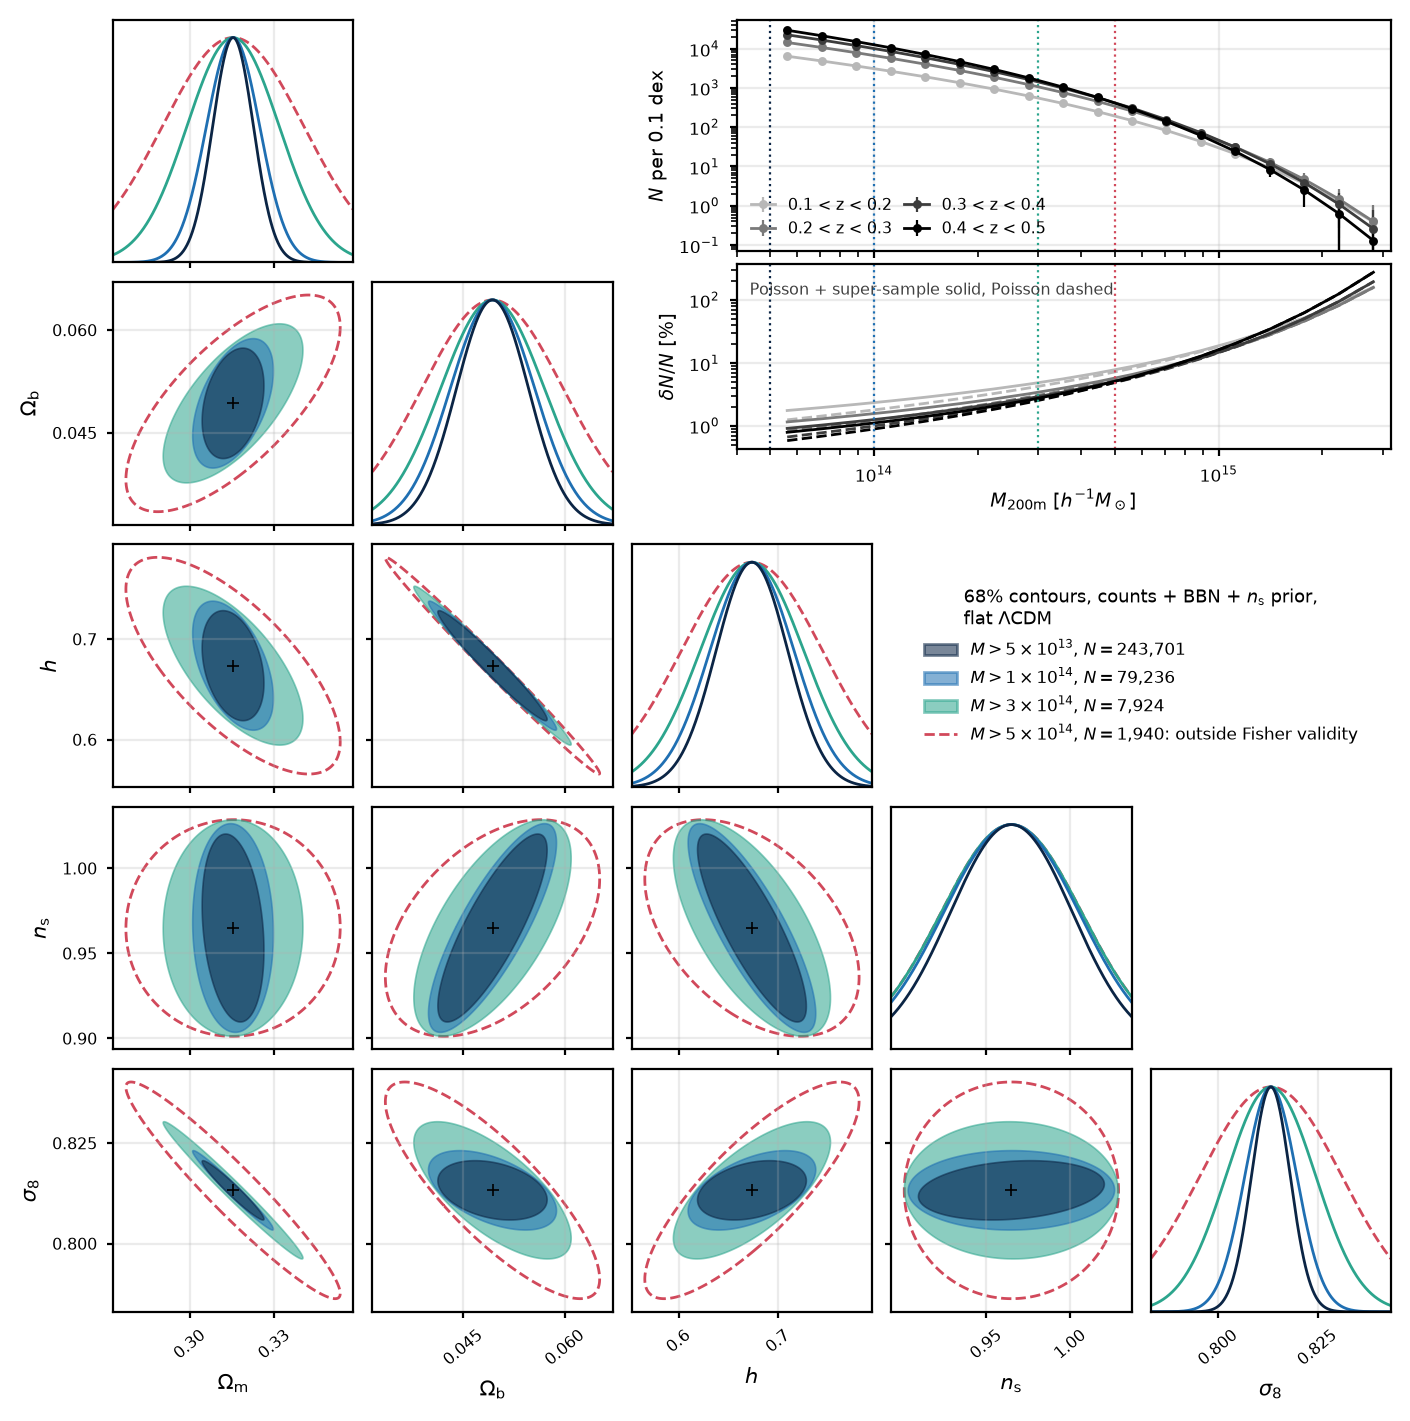

In [8]:
fig = plt.figure(figsize=(7.1, 7.1))
gs = fig.add_gridspec(npar, npar, hspace=0.08, wspace=0.08, left=0.085, right=0.985, bottom=0.075, top=0.985)
half = 1.7 * np.sqrt(np.diag(cov8[THRESH[-1]]))
lims = [(v - h, v + h) for v, h in zip(t08, half)]
F._fisher_corner(fig, gs, PS8, t08, cov8, THRESH, F._HMF_COLOUR, invalid, lims)

sub = gs[0:2, 2:5].subgridspec(3, 2, height_ratios=(1.25, 1.0, 0.34), width_ratios=(0.16, 1.0), hspace=0.08, wspace=0.0)
an, ae = fig.add_subplot(sub[0, 1]), fig.add_subplot(sub[1, 1])
lo, _, _ = aux["bins"][0]
mc = 10.0 ** (lo + 0.5 * F._HMF_DLOGM)
n, cp, ct = n0[0], C[0][0], C[0][1]
ep = np.sqrt(np.diag(cp)).reshape(n.shape)
et = np.sqrt(np.diag(ct)).reshape(n.shape)
grey = np.linspace(0.72, 0.0, len(SHELLS))
for a, (z1, z2) in enumerate(SHELLS):
    an.errorbar(mc, n[a], yerr=et[a], color=str(grey[a]), lw=1.0, ms=2.2, marker="o", capsize=0, elinewidth=0.8,
                label=f"{z1:g} < z < {z2:g}")
    ae.plot(mc, 100 * et[a] / n[a], color=str(grey[a]), lw=1.0)
    ae.plot(mc, 100 * ep[a] / n[a], color=str(grey[a]), lw=1.0, ls="--")
for a_ in (an, ae):
    a_.set_xscale("log")
    a_.set_yscale("log")
    a_.tick_params(labelsize=6.2, length=2.5)
    a_.set_xlim(4e13, 10**F._HMF_LOGM_MAX)
    for th, col in zip(THRESH, F._HMF_COLOUR):
        a_.axvline(th, color=col, lw=0.8, ls=":")
an.set_ylabel(r"$N$ per 0.1 dex", fontsize=7)
an.tick_params(labelbottom=False)
an.legend(fontsize=5.6, ncol=2, loc="lower left", frameon=False, handlelength=1.6, columnspacing=0.8)
ae.set_ylabel(r"$\delta N/N$ [%]", fontsize=7)
ae.set_xlabel(r"$M_{200{\rm m}}$ [$h^{-1}M_\odot$]", fontsize=7, labelpad=1)
ae.text(0.02, 0.9, "Poisson + super-sample solid, Poisson dashed", transform=ae.transAxes, fontsize=5.8,
        color="0.25", va="top")
al = fig.add_subplot(gs[2, 3:5])
al.axis("off")
hand = [Line2D([], [], color=col, ls="--", lw=1.0) if th in invalid else Patch(fc=col, ec=col, alpha=0.55)
        for th, col in zip(THRESH, F._HMF_COLOUR)]
labs = []
for i, th in enumerate(THRESH):
    m_, e_ = f"{th:.0e}".split("e")
    count = f"{n0[i].sum():,.0f}".replace(",", r"{,}")
    labs.append(rf"$M > {m_}\times10^{{{int(e_)}}}$, $N = {count}$"
                + (": outside Fisher validity" if th in invalid else ""))
al.legend(hand, labs, loc="center", fontsize=6.0, frameon=False,
          title="68% contours, counts + BBN + $n_{\\rm s}$ prior,\nflat $\\Lambda$CDM", title_fontsize=6.4);
T.save_figure(fig, "fig_hmf_fisher")

This is the limit of a perfect census.
A survey that finds clusters by their X-ray emission or their Sunyaev–Zel'dovich signal measures neither the mass nor the completeness, and a forecast that includes them would degrade the one above.

## Exercises

1. Drop the super-sample term (use `st["Fp"]`). At which threshold does it matter, and why there?
2. Replace `tinker08` by another fit of notebook 05 in the counts, keep the Fisher matrix of `tinker08`, and compute the shift in $\sigma_8$ that a wrong mass function causes (Eq. 49 of the paper, the bias of a Fisher forecast). Compare it with $\sigma(\sigma_8)$. Notebook 10 does this systematically.
3. Add a 10 per cent Gaussian scatter in $\ln M$ to the counts (convolve ${\rm d}n/{\rm d}\ln M$). How much do the errors grow if the scatter is known, and if it is free?

Next: notebook 10, the accuracy required of the halo layer.